Imports e Paths

In [91]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, log_loss

In [92]:
PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "dataset.csv"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
METRICS_DIR = OUTPUT_DIR / "metrics"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
FIGURES_DIR = OUTPUT_DIR / "figures"

for folder in [METRICS_DIR, PREDICTIONS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(DATASET_PATH)
print(DATASET_PATH.exists())

c:\Users\duart\OneDrive\Ambiente de Trabalho\Classes\semestre2\IAP\project\data\processed\dataset.csv
True


Carregar Dados

In [93]:
CLASSES = ["A", "D", "H"]

FEATURES_NO_ODDS = [
    "ht_form",
    "at_form",
    "ht_attack",
    "at_attack",
    "joint_attack",
    "h2h_dominance",
]

FEATURES_WITH_ODDS = FEATURES_NO_ODDS + [
    "odds_favorite",
]

TARGET = "result"

In [94]:
df = pd.read_csv(DATASET_PATH, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

# Para começar, usamos o modelo sem odds.
# Depois podemos repetir com FEATURES_WITH_ODDS.
features = FEATURES_NO_ODDS

data = df[["date", *features, TARGET]].copy()

for col in features:
    data[col] = data[col].astype(str)

data[TARGET] = data[TARGET].astype(str)

data.head()

,date,ht_form,at_form,ht_attack,at_attack,joint_attack,h2h_dominance,result
0,2006-01-06,good,below avg,average,average,average x average,balanced,A
1,2006-01-06,average,average,average,weak,average x weak,balanced,D
2,2006-01-07,average,average,average,average,average x average,balanced,D
3,2006-01-07,poor,poor,weak,weak,weak x weak,balanced,H
4,2006-01-07,poor,good,weak,above avg,weak x above avg,balanced,H


Split Temporal: Train / Validation / Test

In [95]:
def temporal_train_cal_test_split(data, train_size=0.6, cal_size=0.2):
    n = len(data)

    train_end = int(n * train_size)
    cal_end = int(n * (train_size + cal_size))

    train_df = data.iloc[:train_end].copy()
    cal_df = data.iloc[train_end:cal_end].copy()
    test_df = data.iloc[cal_end:].copy()

    return train_df, cal_df, test_df


train_df, cal_df, test_df = temporal_train_cal_test_split(data)

print("Train:", train_df.shape)
print("Calibration:", cal_df.shape)
print("Test:", test_df.shape)

print(train_df["date"].min(), train_df["date"].max())
print(cal_df["date"].min(), cal_df["date"].max())
print(test_df["date"].min(), test_df["date"].max())

Train: (3349, 8)
Calibration: (1117, 8)
Test: (1117, 8)
2006-01-06 00:00:00 2018-11-04 00:00:00
2018-11-04 00:00:00 2022-04-24 00:00:00
2022-04-25 00:00:00 2026-01-26 00:00:00


Modelo Naive Bayes

In [96]:
def build_naive_bayes_model(alpha=1.0):
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                features,
            )
        ],
        remainder="drop",
    )

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", MultinomialNB(alpha=alpha)),
        ]
    )

    return model

In [97]:
X_train = train_df[features]
y_train = train_df[TARGET]

X_cal = cal_df[features]
y_cal = cal_df[TARGET]

X_test = test_df[features]
y_test = test_df[TARGET]

nb_model = build_naive_bayes_model(alpha=1.0)
nb_model.fit(X_train, y_train)

print("Classes do modelo:", nb_model.named_steps["classifier"].classes_)

Classes do modelo: ['A' 'D' 'H']


Métricas: Accuracy, Log Loss e Brier Score

In [98]:
def predict_proba_df(model, X):
    probs = model.predict_proba(X)
    model_classes = model.named_steps["classifier"].classes_

    probs_df = pd.DataFrame(probs, columns=model_classes, index=X.index)

    for cls in CLASSES:
        if cls not in probs_df.columns:
            probs_df[cls] = 0.0

    return probs_df[CLASSES]


def multiclass_brier_score(y_true, probs_df, classes=CLASSES):
    y_onehot = label_binarize(y_true, classes=classes)
    probs = probs_df[classes].to_numpy()
    return np.mean(np.sum((probs - y_onehot) ** 2, axis=1))


def evaluate_probabilistic_classifier(y_true, probs_df, classes=CLASSES):
    y_pred = probs_df.idxmax(axis=1)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "log_loss": log_loss(y_true, probs_df[classes], labels=classes),
        "brier_score": multiclass_brier_score(y_true, probs_df, classes),
    }

In [99]:
test_probs = predict_proba_df(nb_model, X_test)
test_metrics = evaluate_probabilistic_classifier(y_test, test_probs)

test_metrics

{'accuracy': 0.5299910474485229,
 'log_loss': 1.1091980192845021,
 'brier_score': np.float64(0.6177238721698336)}

In [100]:
metrics_df = pd.DataFrame(
    [
        {
            "model": "naive_bayes_no_odds",
            **test_metrics,
        }
    ]
)

metrics_df.to_csv(METRICS_DIR / "part2_naive_bayes_metrics.csv", index=False)
metrics_df

,model,accuracy,log_loss,brier_score
0,naive_bayes_no_odds,0.529991,1.109198,0.617724


In [101]:
predictions_df = test_df[["date", TARGET]].copy()
predictions_df["predicted_result"] = test_probs.idxmax(axis=1)

for cls in CLASSES:
    predictions_df[f"p_{cls}"] = test_probs[cls]

predictions_df.to_csv(
    PREDICTIONS_DIR / "part2_naive_bayes_predictions.csv",
    index=False,
)

predictions_df.head()

,date,result,predicted_result,p_A,p_D,p_H
4466,2022-04-25,A,A,0.778332,0.170804,0.050864
4467,2022-04-25,H,A,0.945773,0.047287,0.006940
4468,2022-04-29,H,H,0.206279,0.353077,0.440643
4469,2022-04-30,A,A,0.725238,0.208730,0.066032
4470,2022-04-30,H,H,0.140994,0.417932,0.441074


Reliability Diagram e ECE

In [102]:
def reliability_bins(y_true, probs_df, n_bins=10):
    confidences = probs_df.max(axis=1).to_numpy()
    predictions = probs_df.idxmax(axis=1).to_numpy()
    correct = (predictions == np.array(y_true)).astype(int)

    bins = np.linspace(0.0, 1.0, n_bins + 1)

    rows = []
    for i in range(n_bins):
        left = bins[i]
        right = bins[i + 1]

        if i == n_bins - 1:
            mask = (confidences >= left) & (confidences <= right)
        else:
            mask = (confidences >= left) & (confidences < right)

        if mask.sum() == 0:
            rows.append({
                "bin": i,
                "bin_left": left,
                "bin_right": right,
                "n": 0,
                "confidence": np.nan,
                "accuracy": np.nan,
            })
        else:
            rows.append({
                "bin": i,
                "bin_left": left,
                "bin_right": right,
                "n": int(mask.sum()),
                "confidence": float(confidences[mask].mean()),
                "accuracy": float(correct[mask].mean()),
            })

    return pd.DataFrame(rows)


def expected_calibration_error(reliability_df, total_n):
    valid = reliability_df.dropna(subset=["confidence", "accuracy"]).copy()
    return np.sum(
        (valid["n"] / total_n) * np.abs(valid["accuracy"] - valid["confidence"])
    )

In [103]:
reliability_df = reliability_bins(y_test, test_probs, n_bins=10)
ece = expected_calibration_error(reliability_df, total_n=len(y_test))

print("ECE:", ece)
reliability_df

ECE: 0.1344716561221167


,bin,bin_left,bin_right,n,confidence,accuracy
0,0,0.0,0.1,0,NaN,NaN
1,1,0.1,0.2,0,NaN,NaN
2,2,0.2,0.3,0,NaN,NaN
3,3,0.3,0.4,61,0.382209,0.393443
4,4,0.4,0.5,367,0.443494,0.403270
5,5,0.5,0.6,102,0.548252,0.392157
6,6,0.6,0.7,76,0.650274,0.447368
7,7,0.7,0.8,137,0.753620,0.576642
8,8,0.8,0.9,101,0.847277,0.574257
9,9,0.9,1.0,273,0.954557,0.765568


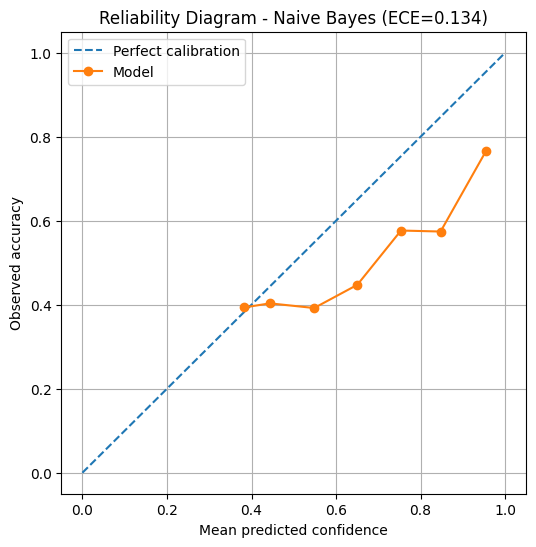

In [104]:
def plot_reliability_diagram(reliability_df, title, output_path=None):
    plt.figure(figsize=(6, 6))

    plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    plt.plot(
        reliability_df["confidence"],
        reliability_df["accuracy"],
        marker="o",
        label="Model",
    )

    plt.xlabel("Mean predicted confidence")
    plt.ylabel("Observed accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(True)

    if output_path is not None:
        plt.savefig(output_path, bbox_inches="tight", dpi=150)

    plt.show()


plot_reliability_diagram(
    reliability_df,
    title=f"Reliability Diagram - Naive Bayes (ECE={ece:.3f})",
    output_path=FIGURES_DIR / "part2_reliability_naive_bayes.png",
)

In [105]:
reliability_df.to_csv(
    METRICS_DIR / "part2_reliability_naive_bayes.csv",
    index=False,
)

Modelo Calibrado

Classes do modelo: ['A' 'D' 'H']
Calibrated ECE: 0.03593368559417018
Test Metrics:
{'accuracy': 0.5299910474485229, 'log_loss': 1.1091980192845021, 'brier_score': np.float64(0.6177238721698336)}


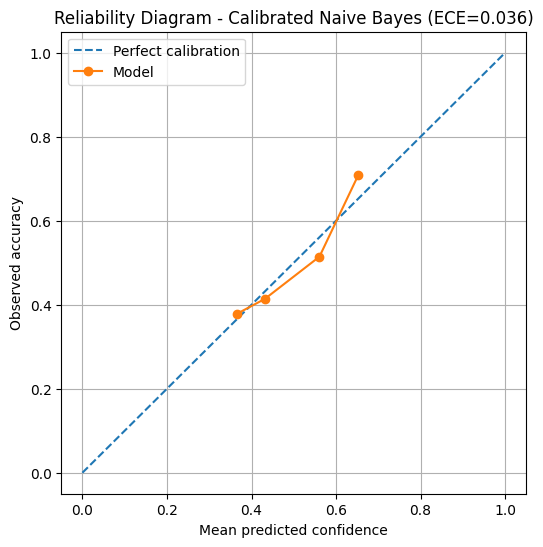

,date,result,predicted_result,p_A,p_D,p_H,model_confidence
4466,2022-04-25,A,A,0.594369,0.214253,0.191377,0.594369
4467,2022-04-25,H,A,0.661088,0.171172,0.167740,0.661088
4468,2022-04-29,H,H,0.274657,0.302362,0.422981,0.422981
4469,2022-04-30,A,A,0.570116,0.229595,0.200288,0.570116
4470,2022-04-30,H,H,0.242480,0.331341,0.426179,0.426179


In [106]:
from sklearn.calibration import CalibratedClassifierCV

def predict_proba_df(model, X, classes=CLASSES):
    probs = model.predict_proba(X)

    if hasattr(model, "classes_"):
        model_classes = model.classes_
    elif hasattr(model, "named_steps"):
        model_classes = model.named_steps["classifier"].classes_
    else:
        raise AttributeError(
            "Não foi possível encontrar as classes do modelo."
        )

    probs_df = pd.DataFrame(
        probs,
        columns=model_classes,
        index=X.index,
    )

    return probs_df[classes]

# model.fit(X_train, y_train)
X_train = train_df[features]
y_train = train_df[TARGET]

X_cal = cal_df[features]
y_cal = cal_df[TARGET]

X_test = test_df[features]
y_test = test_df[TARGET]

model = build_naive_bayes_model(alpha=1.0)
model.fit(X_train, y_train)

print("Classes do modelo:", model.named_steps["classifier"].classes_)

try:
    # scikit-learn mais recente
    from sklearn.frozen import FrozenEstimator

    calibrated_model = CalibratedClassifierCV(
        estimator=FrozenEstimator(model),
        method="sigmoid",
    )

    calibrated_model.fit(X_cal, y_cal)

except ImportError:
    # scikit-learn mais antigo
    calibrated_model = CalibratedClassifierCV(
        estimator=model,
        method="sigmoid",
        cv="prefit",
    )

    calibrated_model.fit(X_cal, y_cal)

calibrated_test_probs = predict_proba_df(calibrated_model, X_test)
calibrated_test_probs.head()

calibrated_metrics = evaluate_probabilistic_classifier(
    y_test,
    calibrated_test_probs,
)

calibrated_reliability_df = reliability_bins(
    y_test,
    calibrated_test_probs,
    n_bins=10,
)

calibrated_ece = expected_calibration_error(
    calibrated_reliability_df,
    total_n=len(y_test),
)

print("Calibrated ECE:", calibrated_ece)

test_probs = predict_proba_df(model, X_test)
test_metrics = evaluate_probabilistic_classifier(y_test, test_probs)

print("Test Metrics:")
print(test_metrics)

plot_reliability_diagram(
    calibrated_reliability_df,
    title=f"Reliability Diagram - Calibrated Naive Bayes (ECE={calibrated_ece:.3f})",
    output_path=FIGURES_DIR / "part2_reliability_naive_bayes_calibrated.png",
)

ppredictions_df = test_df[["date", TARGET]].copy()
predictions_df["predicted_result"] = calibrated_test_probs.idxmax(axis=1)
predictions_df["model_confidence"] = calibrated_test_probs.max(axis=1)

for cls in CLASSES:
    predictions_df[f"p_{cls}"] = calibrated_test_probs[cls]
    
predictions_df.to_csv(
    PREDICTIONS_DIR / "part2_naive_bayes_calibrated_predictions.csv",
    index=False,
)

predictions_df.head()

In [107]:
calibrated_reliability_df

,bin,bin_left,bin_right,n,confidence,accuracy
0,0,0.0,0.1,0,NaN,NaN
1,1,0.1,0.2,0,NaN,NaN
2,2,0.2,0.3,0,NaN,NaN
3,3,0.3,0.4,148,0.365547,0.378378
4,4,0.4,0.5,372,0.431786,0.413978
5,5,0.5,0.6,208,0.560719,0.514423
6,6,0.6,0.7,389,0.652995,0.709512
7,7,0.7,0.8,0,NaN,NaN
8,8,0.8,0.9,0,NaN,NaN
9,9,0.9,1.0,0,NaN,NaN


Conformal Prediction

In [108]:
def conformal_threshold(model, X_cal, y_cal, alpha=0.1, classes=CLASSES):
    cal_probs = predict_proba_df(model, X_cal)

    true_class_probs = np.array([
        cal_probs.loc[idx, true_label]
        for idx, true_label in zip(cal_probs.index, y_cal)
    ])

    scores = 1.0 - true_class_probs

    n_cal = len(scores)
    k = int(np.ceil((1 - alpha) * (n_cal + 1)))

    sorted_scores = np.sort(scores)

    if k > n_cal:
        q_hat = np.inf
    else:
        q_hat = sorted_scores[k - 1]

    return q_hat, scores


def conformal_prediction_sets(model, X, q_hat, classes=CLASSES):
    probs_df = predict_proba_df(model, X)

    prediction_sets = []
    for _, row in probs_df.iterrows():
        labels = [
            cls
            for cls in classes
            if 1.0 - row[cls] <= q_hat
        ]
        prediction_sets.append(labels)

    return prediction_sets, probs_df


def evaluate_conformal_sets(y_true, prediction_sets):
    y_true = list(y_true)

    contains_true = [
        true_label in pred_set
        for true_label, pred_set in zip(y_true, prediction_sets)
    ]

    set_sizes = [len(pred_set) for pred_set in prediction_sets]

    return {
        "coverage": np.mean(contains_true),
        "average_set_size": np.mean(set_sizes),
        "singleton_rate": np.mean([size == 1 for size in set_sizes]),
        "empty_set_rate": np.mean([size == 0 for size in set_sizes]),
    }

In [109]:
alpha = 0.1  # 90% coverage desejada

q_hat, cal_scores = conformal_threshold(
    nb_model,
    X_cal,
    y_cal,
    alpha=alpha,
)

test_sets, test_probs = conformal_prediction_sets(
    nb_model,
    X_test,
    q_hat,
)

conformal_metrics = evaluate_conformal_sets(y_test, test_sets)

print("q_hat:", q_hat)
conformal_metrics

q_hat: 0.9038420884497305


{'coverage': np.float64(0.891674127126231),
 'average_set_size': np.float64(2.270367054610564),
 'singleton_rate': np.float64(0.2730528200537153),
 'empty_set_rate': np.float64(0.0)}

In [110]:
conformal_df = predictions_df.copy()
conformal_df["prediction_set"] = [
    ",".join(pred_set)
    for pred_set in test_sets
]
conformal_df["set_size"] = [
    len(pred_set)
    for pred_set in test_sets
]
conformal_df["contains_true"] = [
    true_label in pred_set
    for true_label, pred_set in zip(y_test, test_sets)
]

conformal_df.to_csv(
    PREDICTIONS_DIR / "part2_conformal_prediction_sets.csv",
    index=False,
)

conformal_metrics_df = pd.DataFrame([
    {
        "model": "naive_bayes_no_odds",
        "alpha": alpha,
        "target_coverage": 1 - alpha,
        "q_hat": q_hat,
        **conformal_metrics,
    }
])

conformal_metrics_df.to_csv(
    METRICS_DIR / "part2_conformal_metrics.csv",
    index=False,
)

conformal_metrics_df

,model,alpha,target_coverage,q_hat,coverage,average_set_size,singleton_rate,empty_set_rate
0,naive_bayes_no_odds,0.1,0.9,0.903842,0.891674,2.270367,0.273053,0.0


Bayesian Optimization

In [111]:
#pip install scikit-optimize

In [112]:
from skopt import BayesSearchCV
from skopt.space import Real
from sklearn.model_selection import TimeSeriesSplit

In [113]:
search_model = build_naive_bayes_model()

search_space = {
    "classifier__alpha": Real(1e-3, 10.0, prior="log-uniform"),
}

tscv = TimeSeriesSplit(n_splits=5)

bayes_search = BayesSearchCV(
    estimator=search_model,
    search_spaces=search_space,
    n_iter=25,
    scoring="neg_log_loss",
    cv=tscv,
    n_jobs=-1,
    random_state=42,
)

bayes_search.fit(X_train, y_train)

print("Best params:", bayes_search.best_params_)
print("Best CV score:", bayes_search.best_score_)

Best params: OrderedDict({'classifier__alpha': 10.0})
Best CV score: -1.0586217829411804


In [114]:
best_nb_model = bayes_search.best_estimator_

best_test_probs = predict_proba_df(best_nb_model, X_test)
best_test_metrics = evaluate_probabilistic_classifier(y_test, best_test_probs)

best_test_metrics

{'accuracy': 0.5299910474485229,
 'log_loss': 1.0739906825127543,
 'brier_score': np.float64(0.6093188885348171)}

In [115]:
comparison_df = pd.DataFrame([
    {
        "model": "naive_bayes_alpha_1",
        **test_metrics,
    },
    {
        "model": "naive_bayes_bayesopt",
        **best_test_metrics,
    },
])

comparison_df.to_csv(
    METRICS_DIR / "part2_naive_bayes_comparison.csv",
    index=False,
)

comparison_df

,model,accuracy,log_loss,brier_score
0,naive_bayes_alpha_1,0.529991,1.109198,0.617724
1,naive_bayes_bayesopt,0.529991,1.073991,0.609319


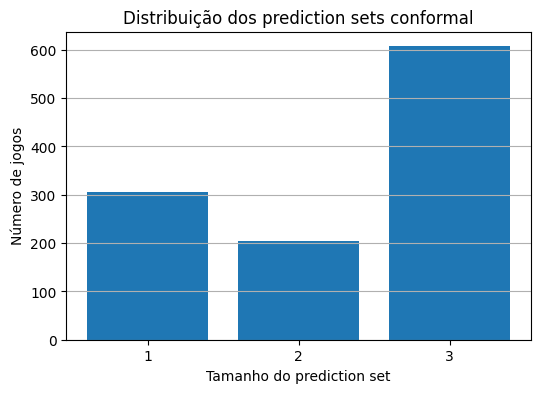

In [116]:
conformal_df = pd.read_csv(PREDICTIONS_DIR / "part2_conformal_prediction_sets.csv")

set_size_counts = conformal_df["set_size"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(set_size_counts.index.astype(str), set_size_counts.values)
plt.xlabel("Tamanho do prediction set")
plt.ylabel("Número de jogos")
plt.title("Distribuição dos prediction sets conformal")
plt.grid(axis="y")
plt.savefig(FIGURES_DIR / "part2_conformal_set_size_distribution.png", bbox_inches="tight", dpi=150)
plt.show()

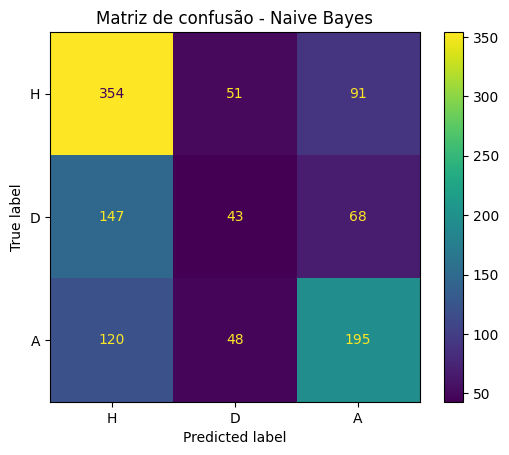

In [117]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

preds = pd.read_csv(PREDICTIONS_DIR / "part2_naive_bayes_predictions.csv")

cm = confusion_matrix(
    preds["result"],
    preds["predicted_result"],
    labels=["H", "D", "A"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["H", "D", "A"]
)

disp.plot(values_format="d")
plt.title("Matriz de confusão - Naive Bayes")
plt.savefig(FIGURES_DIR / "part2_confusion_matrix_naive_bayes.png", bbox_inches="tight", dpi=150)
plt.show()